In [ ]:
import kagglehub

# Download official Indian Food Images dataset from Kaggle
path = kagglehub.dataset_download("iamsouravbanerjee/indian-food-images-dataset")
print("Images dataset path:", path)

Using Colab cache for faster access to the 'indian-food-images-dataset' dataset.
Images dataset path: /kaggle/input/indian-food-images-dataset


Imports and settings

In [ ]:
import os, re, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)
print("Dataset path:", path)

TensorFlow: 2.21.0
Dataset path: /kaggle/input/indian-food-images-dataset


Check the dataset folder structure

In [ ]:
for root, dirs, files in os.walk(path):
    depth = root.replace(path, "").count(os.sep)
    if depth <= 3:
        print("  " * depth + f"{os.path.basename(root)}/  ({len(files)} files)")

indian-food-images-dataset/  (1 files)
  Indian Food Images/  (0 files)
    Indian Food Images/  (0 files)
      mysore_pak/  (50 files)
      ghevar/  (50 files)
      sohan_papdi/  (50 files)
      ras_malai/  (50 files)
      ariselu/  (50 files)
      kofta/  (50 files)
      aloo_tikki/  (50 files)
      gajar_ka_halwa/  (50 files)
      chhena_kheeri/  (50 files)
      kakinada_khaja/  (50 files)
      lassi/  (50 files)
      naan/  (50 files)
      chak_hao_kheer/  (50 files)
      butter_chicken/  (50 files)
      kajjikaya/  (50 files)
      chicken_razala/  (50 files)
      lyangcha/  (50 files)
      aloo_gobi/  (50 files)
      dal_makhani/  (50 files)
      bandar_laddu/  (50 files)
      bhindi_masala/  (50 files)
      unni_appam/  (50 files)
      kuzhi_paniyaram/  (50 files)
      sandesh/  (50 files)
      sohan_halwa/  (50 files)
      rasgulla/  (50 files)
      shankarpali/  (50 files)
      pithe/  (50 files)
      imarti/  (50 files)
      misti_doi/  (50 files)

Collect all image paths and labels into a DataFrame

This merges the dataset's own training, validation and evaluation folders into one pool, so we can re-split it ourselves with sklearn.

In [ ]:
# Inspect downloaded Indian food dataset structure
import os
for root, dirs, files in os.walk(path):
    depth = root.replace(path, "").count(os.sep)
    if depth <= 2:
        print("  " * depth + f"{os.path.basename(root)}/  ({len(files)} files)")

indian-food-images-dataset/  (1 files)
  Indian Food Images/  (0 files)
    Indian Food Images/  (0 files)


In [ ]:
CLASS_NAMES = ["Bread", "Dairy product", "Dessert", "Egg", "Fried food", "Meat",
               "Noodles-Pasta", "Rice", "Seafood", "Soup", "Vegetable-Fruit"]
SPLIT_DIRS = {"training", "validation", "evaluation", "train", "val", "test"}
EXTS = (".jpg", ".jpeg", ".png")

def get_label(fp):
    parent = os.path.basename(os.path.dirname(fp))
    if parent.lower() in SPLIT_DIRS:                  # flat layout: label from filename like 3_123.jpg
        m = re.match(r"(\d+)_", os.path.basename(fp))
        return CLASS_NAMES[int(m.group(1))] if m else None
    if parent.isdigit():                              # folders named 0..10
        return CLASS_NAMES[int(parent)]
    return parent                                     # folders named by class

rows = []
for root, _, files in os.walk(path):
    for f in files:
        if f.lower().endswith(EXTS):
            fp = os.path.join(root, f)
            rows.append((fp, get_label(fp)))

df = pd.DataFrame(rows, columns=["filepath", "label"]).dropna()
print("Total images:", len(df))
print("Classes:", df["label"].nunique())
df.head()

Total images: 4000
Classes: 80


,filepath,label
0,/kaggle/input/indian-food-images-dataset/India...,mysore_pak
1,/kaggle/input/indian-food-images-dataset/India...,mysore_pak
2,/kaggle/input/indian-food-images-dataset/India...,mysore_pak
3,/kaggle/input/indian-food-images-dataset/India...,mysore_pak
4,/kaggle/input/indian-food-images-dataset/India...,mysore_pak


Dataset analysis (class balance and sample images)

label
mysore_pak              50
ghevar                  50
sohan_papdi             50
ras_malai               50
ariselu                 50
                        ..
aloo_shimla_mirch       50
gulab_jamun             50
paneer_butter_masala    50
modak                   50
biryani                 50
Name: count, Length: 80, dtype: int64


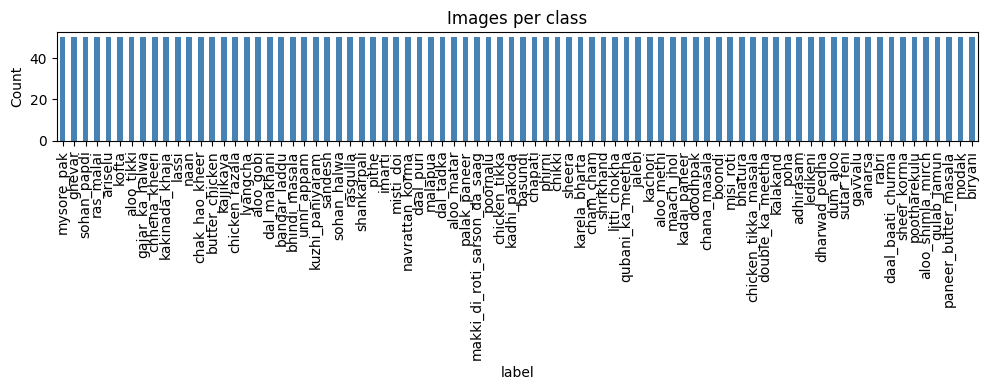

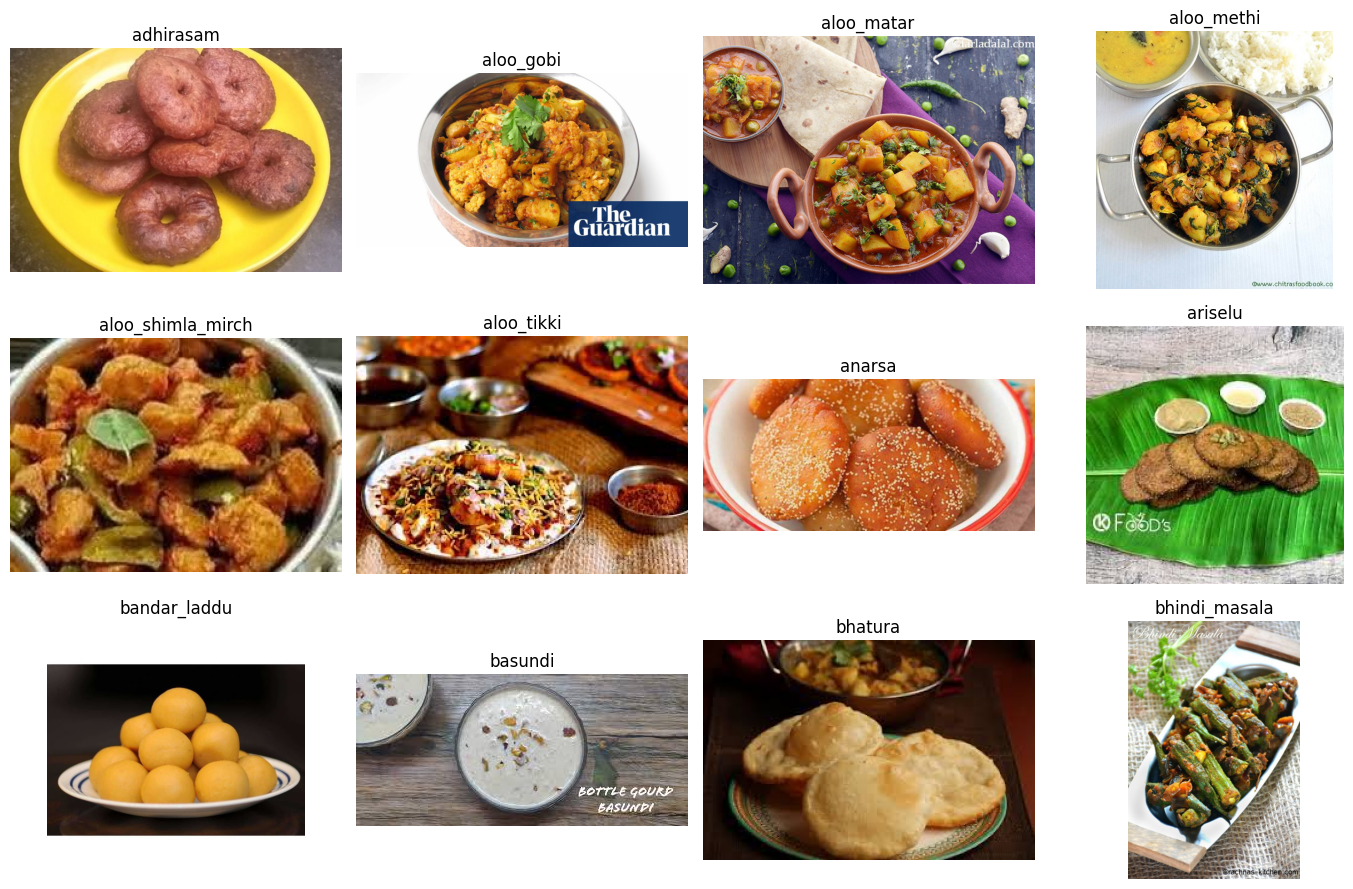

In [ ]:
counts = df["label"].value_counts()
print(counts)

plt.figure(figsize=(10, 4))
counts.plot(kind="bar", color="steelblue")
plt.title("Images per class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

classes = sorted(df["label"].unique())
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, cls in zip(axes.ravel(), classes):
    fp = df[df["label"] == cls].sample(1, random_state=SEED)["filepath"].values[0]
    ax.imshow(plt.imread(fp))
    ax.set_title(cls)
    ax.axis("off")
for ax in axes.ravel()[len(classes):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Encode labels and split with sklearn (80% train, 10% validation, 10% test)

In [ ]:
import os, re
import pandas as pd

# Target everyday Indian dishes matching our nutrition database
TARGET_DISHES = [
    "biryani", "butter_chicken", "chole_bhature", "dal_makhani",
    "dosa", "gulab_jamun", "idli", "paneer_tikka", "pav_bhaji", "samosa"
]

# Locate subdirectories inside downloaded Kaggle path
EXTS = (".jpg", ".jpeg", ".png")
rows = []
for root, dirs, files in os.walk(path):
    folder_name = os.path.basename(root).lower().replace("-", "_").replace(" ", "_")
    matched_label = None
    for dish in TARGET_DISHES:
        if dish in folder_name or folder_name in dish:
            matched_label = dish
            break
    if matched_label:
        for f in files:
            if f.lower().endswith(EXTS):
                rows.append((os.path.join(root, f), matched_label))

df = pd.DataFrame(rows, columns=["filepath", "label"]).dropna()
print("Total images collected:", len(df))
print("Classes found:", df["label"].nunique())
print(df["label"].value_counts())
df.head()

Total images collected: 200
Classes found: 4
label
butter_chicken    50
dal_makhani       50
gulab_jamun       50
biryani           50
Name: count, dtype: int64


,filepath,label
0,/kaggle/input/indian-food-images-dataset/India...,butter_chicken
1,/kaggle/input/indian-food-images-dataset/India...,butter_chicken
2,/kaggle/input/indian-food-images-dataset/India...,butter_chicken
3,/kaggle/input/indian-food-images-dataset/India...,butter_chicken
4,/kaggle/input/indian-food-images-dataset/India...,butter_chicken


In [ ]:
le = LabelEncoder()
df["label_id"] = le.fit_transform(df["label"])
class_names = list(le.classes_)
NUM_CLASSES = len(class_names)
print("Class mapping:", dict(enumerate(class_names)))

# Step 1: 80% train, 20% temp
train_df, temp_df = train_test_split(
    df, test_size=0.20, stratify=df["label_id"], random_state=SEED)

# Step 2: split temp equally into validation (10%) and test (10%)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label_id"], random_state=SEED)

print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")

# Check that class proportions are preserved in each split
pd.DataFrame({
    "train": train_df["label"].value_counts(normalize=True),
    "val":   val_df["label"].value_counts(normalize=True),
    "test":  test_df["label"].value_counts(normalize=True),
}).round(3)

Class mapping: {0: 'biryani', 1: 'butter_chicken', 2: 'dal_makhani', 3: 'gulab_jamun'}
Train: 160 | Validation: 20 | Test: 20


,train,val,test
label,,,
biryani,0.25,0.25,0.25
butter_chicken,0.25,0.25,0.25
dal_makhani,0.25,0.25,0.25
gulab_jamun,0.25,0.25,0.25


Preprocessing and augmentation pipeline

Images are resized to 224×224. Augmentation (flip, rotation, zoom, contrast) is applied to the training set only. Pixel scaling is left for the model stage, because MobileNetV2 and the custom CNN scale pixels differently.

In [ ]:
def load_and_resize(filepath, label):
    img = tf.io.read_file(filepath)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
], name="augmentation")

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (frame["filepath"].values, frame["label_id"].values))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED)
    ds = ds.map(load_and_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    if training:
        ds = ds.map(lambda x, y: (augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df)
test_ds  = make_dataset(test_df)

for images, labels in train_ds.take(1):
    print("Batch shape:", images.shape, "| Labels shape:", labels.shape)
    print("Pixel range:", float(tf.reduce_min(images)), "-", float(tf.reduce_max(images)))

Batch shape: (32, 224, 224, 3) | Labels shape: (32,)
Pixel range: 0.0 - 255.0


Visualise processed training images

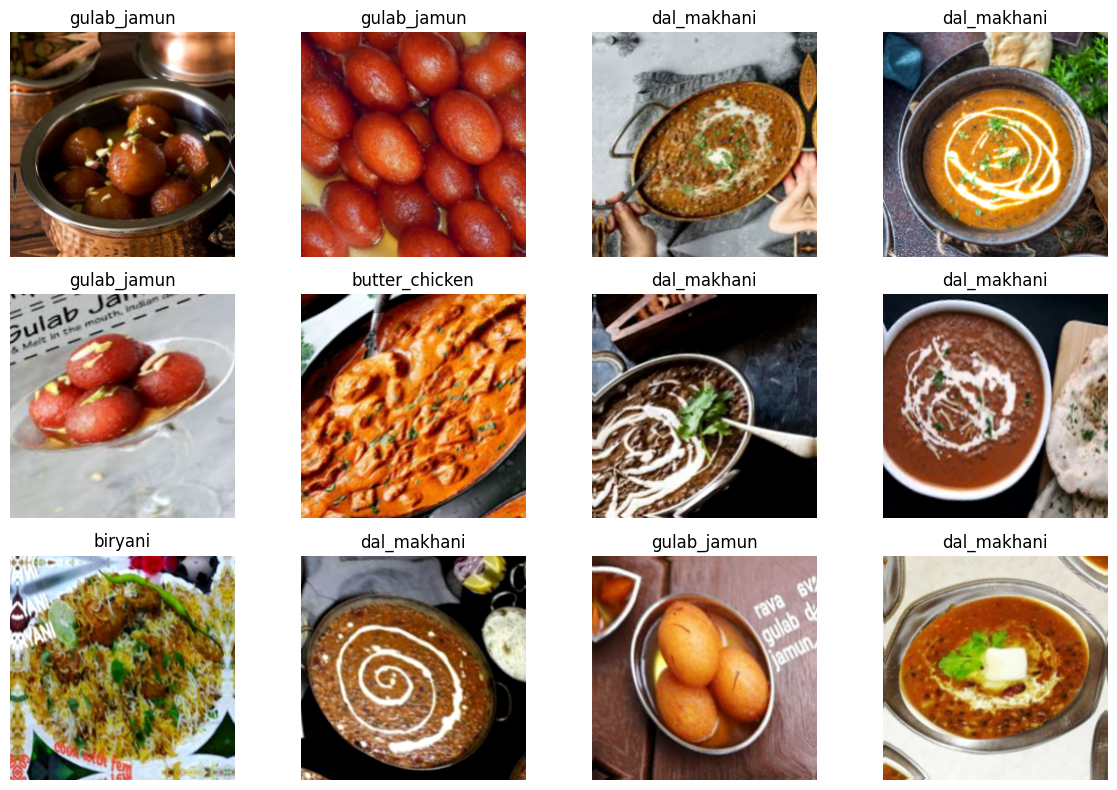

In [ ]:
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()
plt.show()

Imports for modelling

In [ ]:
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
import seaborn as sns

EPOCHS = 20
INPUT_SHAPE = IMG_SIZE + (3,)

def get_callbacks(name):
    return [
        callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
        callbacks.ModelCheckpoint(f"{name}.keras", monitor="val_accuracy", save_best_only=True),
    ]

Build the custom CNN

In [ ]:
def build_custom_cnn():
    model = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        layers.Rescaling(1./255),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(256, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="custom_cnn")
    return model

build_custom_cnn().summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 457,156 (1.74 MB)

 Trainable params: 456,196 (1.74 MB)

 Non-trainable params: 960 (3.75 KB)

Training helper and plotting function

In [ ]:
def get_optimizer(name, lr):
    return {
        "adam":    optimizers.Adam(learning_rate=lr),
        "sgd":     optimizers.SGD(learning_rate=lr, momentum=0.9),
        "rmsprop": optimizers.RMSprop(learning_rate=lr),
    }[name]

def train_model(model, opt_name, lr, tag):
    model.compile(optimizer=get_optimizer(opt_name, lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    history = model.fit(train_ds, validation_data=val_ds,
                        epochs=EPOCHS, callbacks=get_callbacks(tag), verbose=1)
    return history

def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history["accuracy"], label="train")
    ax[0].plot(history.history["val_accuracy"], label="val")
    ax[0].set_title(f"{title} - Accuracy")
    ax[0].legend()
    ax[1].plot(history.history["loss"], label="train")
    ax[1].plot(history.history["val_loss"], label="val")
    ax[1].set_title(f"{title} - Loss")
    ax[1].legend()
    plt.tight_layout()
    plt.show()

Train the custom CNN

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.4688 - loss: 1.3835 - val_accuracy: 0.2500 - val_loss: 1.3816 - learning_rate: 0.0010
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 579ms/step - accuracy: 0.6000 - loss: 1.0691 - val_accuracy: 0.3000 - val_loss: 1.3788 - learning_rate: 0.0010
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 370ms/step - accuracy: 0.6687 - loss: 0.8621 - val_accuracy: 0.3500 - val_loss: 1.3740 - learning_rate: 0.0010
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 591ms/step - accuracy: 0.7063 - loss: 0.7993 - val_accuracy: 0.3000 - val_loss: 1.3879 - learning_rate: 0.0010
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 493ms/step - accuracy: 0.7489 - loss: 0.6123
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 665ms/step - accuracy: 0.7625 - loss: 0.6235 - val_accuracy: 0.2500 - val_loss: 1.4774 - learning_rate: 0.0010
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.8375 - loss: 0.5709 - val_accuracy: 0.2500

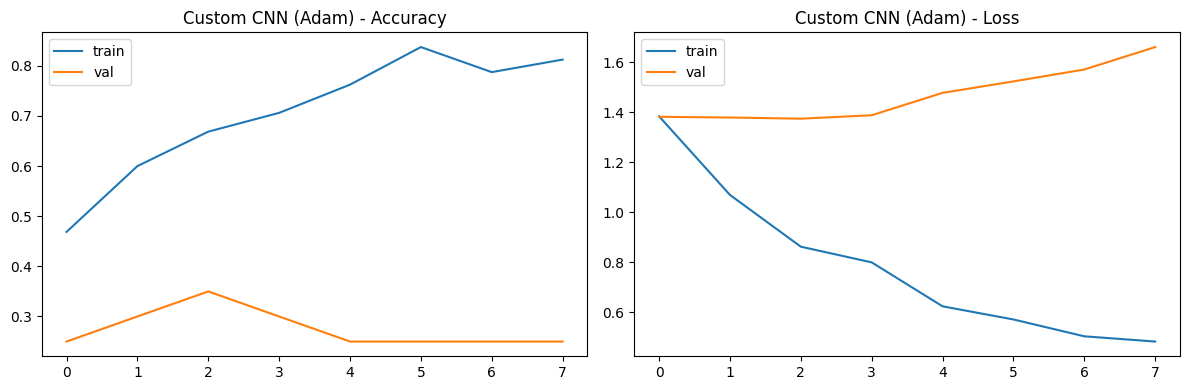

Custom CNN validation accuracy: 0.3500


In [ ]:
cnn_model = build_custom_cnn()
cnn_history = train_model(cnn_model, "adam", 1e-3, "custom_cnn_adam")
plot_history(cnn_history, "Custom CNN (Adam)")

val_loss, val_acc = cnn_model.evaluate(val_ds, verbose=0)
print(f"Custom CNN validation accuracy: {val_acc:.4f}")

In [ ]:
from sklearn.metrics import precision_score, recall_score

In [ ]:

# STEP 1: Prepare datasets for MobileNetV2

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def prepare_mobilenet(images, labels):
    images = preprocess_input(tf.cast(images, tf.float32))
    return images, labels

mobilenet_train_ds = train_ds.map(
    prepare_mobilenet,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

mobilenet_val_ds = val_ds.map(
    prepare_mobilenet,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

mobilenet_test_ds = test_ds.map(
    prepare_mobilenet,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

print("MobileNetV2 datasets prepared successfully!")


MobileNetV2 datasets prepared successfully!


In [ ]:

# STEP 2: Build the model

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

mobilenet_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="mobilenetv2_food_classifier")

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_food_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

# STEP 3: Train MobileNetV2

mobilenet_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        verbose=1
    )
]

mobilenet_history = mobilenet_model.fit(
    mobilenet_train_ds,
    validation_data=mobilenet_val_ds,
    epochs=10,
    callbacks=mobilenet_callbacks,
    verbose=1
)


Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 41s 4s/step - accuracy: 0.3000 - loss: 1.6171 - val_accuracy: 0.4000 - val_loss: 1.2142 - learning_rate: 0.0010
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 329ms/step - accuracy: 0.5312 - loss: 1.1415 - val_accuracy: 0.7500 - val_loss: 0.9392 - learning_rate: 0.0010
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 376ms/step - accuracy: 0.6562 - loss: 0.8525 - val_accuracy: 0.7000 - val_loss: 0.7606 - learning_rate: 0.0010
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 681ms/step - accuracy: 0.7688 - loss: 0.6440 - val_accuracy: 0.7500 - val_loss: 0.6372 - learning_rate: 0.0010
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 372ms/step - accuracy: 0.8125 - loss: 0.5462 - val_accuracy: 0.8500 - val_loss: 0.5580 - learning_rate: 0.0010
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 386ms/step - accuracy: 0.8500 - loss: 0.4671 - val_accuracy: 0.9000 - val_loss: 0.5084 - learning_rate: 0.0010
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 378ms/step - accuracy: 0.8625 - loss: 0.4233 - val_accuracy: 0.

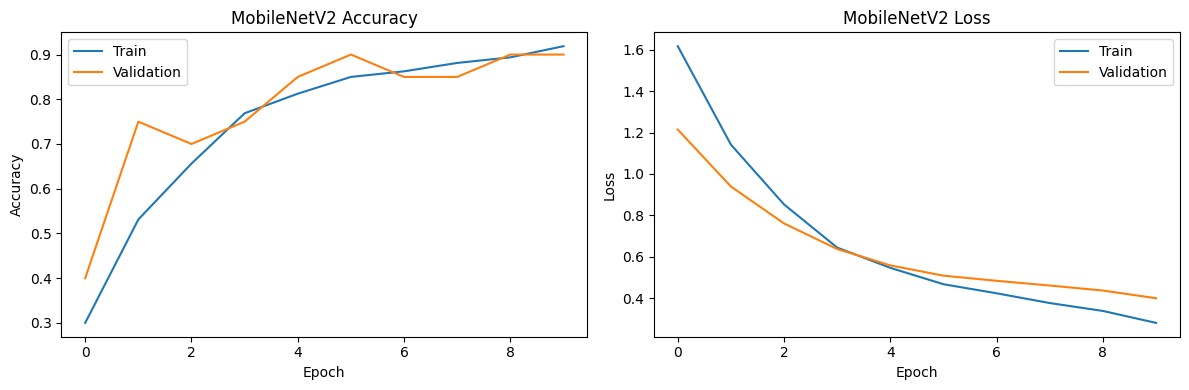

In [ ]:

# STEP 4: Plot training history

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(mobilenet_history.history["accuracy"], label="Train")
plt.plot(mobilenet_history.history["val_accuracy"], label="Validation")
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(mobilenet_history.history["loss"], label="Train")
plt.plot(mobilenet_history.history["val_loss"], label="Validation")
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
MobileNetV2 Test Accuracy: 0.95

Classification Report:

                precision    recall  f1-score   support

       biryani       1.00      1.00      1.00         5
butter_chicken       1.00      0.80      0.89         5
   dal_makhani       0.83      1.00      0.91         5
   gulab_jamun       1.00      1.00      1.00         5

      accuracy                           0.95        20
     macro avg       0.96      0.95      0.95        20
  weighted avg       0.96      0.95      0.95        20



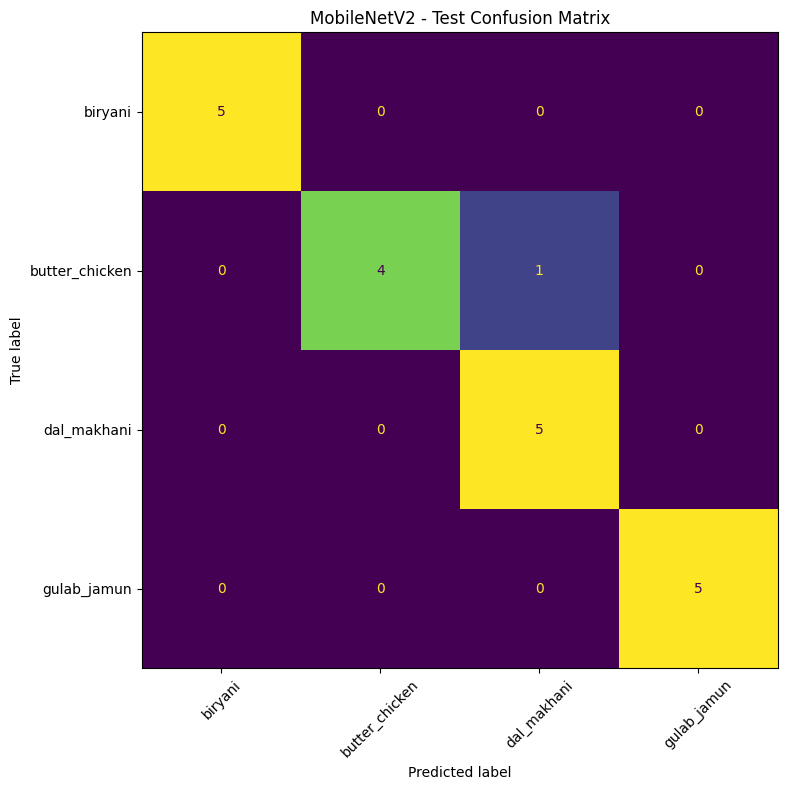

In [ ]:

# STEP 5: Evaluate MobileNetV2

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_true_mobilenet = np.concatenate([
    labels.numpy()
    for images, labels in mobilenet_test_ds
]).astype(int)

y_prob_mobilenet = mobilenet_model.predict(
    mobilenet_test_ds,
    verbose=1
)

y_pred_mobilenet = np.argmax(y_prob_mobilenet, axis=1)

print(
    "MobileNetV2 Test Accuracy:",
    round(accuracy_score(y_true_mobilenet, y_pred_mobilenet), 4)
)

print("\nClassification Report:\n")
print(classification_report(
    y_true_mobilenet,
    y_pred_mobilenet,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0
))

cm_mobilenet = confusion_matrix(
    y_true_mobilenet,
    y_pred_mobilenet,
    labels=np.arange(NUM_CLASSES)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mobilenet,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("MobileNetV2 - Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 6: Save the trained model

mobilenet_model.save("mobilenetv2_food_classifier.keras")

print("Model saved successfully!")


Model saved successfully!


In [ ]:
# STEP 6: Save model, class names, test images & package for Streamlit app
import os, json, shutil
from google.colab import files

os.makedirs("models", exist_ok=True)
os.makedirs("data/test", exist_ok=True)

# 1. Save trained MobileNetV2 model as models/food_model.keras
mobilenet_model.save("models/food_model.keras")
print("Saved models/food_model.keras")

# 2. Save class names JSON (exact alphabetical order of model outputs)
with open("models/class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)
print("Saved models/class_names.json:", class_names)

# 3. Export test split images for Streamlit evaluation tab
for cls in class_names:
    os.makedirs(f"data/test/{cls}", exist_ok=True)
for _, row in test_df.iterrows():
    fname = os.path.basename(row["filepath"])
    shutil.copy(row["filepath"], os.path.join("data", "test", row["label"], fname))
print("Exported test images to data/test/")

# 4. Zip artifacts into a single downloadable file
!zip -r nutrilens_artifacts.zip models/ data/test/
files.download("nutrilens_artifacts.zip")
print("Downloaded nutrilens_artifacts.zip successfully!")

Saved models/food_model.keras
Saved models/class_names.json: ['biryani', 'butter_chicken', 'dal_makhani', 'gulab_jamun']
Exported test images to data/test/
  adding: models/ (stored 0%)
  adding: models/class_names.json (deflated 19%)
  adding: models/food_model.keras (deflated 12%)
  adding: data/test/ (stored 0%)
  adding: data/test/biryani/ (stored 0%)
  adding: data/test/biryani/19a505bf7e.jpg (deflated 2%)
  adding: data/test/biryani/7dd0b5855c.jpg (deflated 3%)
  adding: data/test/biryani/46fab26bdd.jpg (deflated 3%)
  adding: data/test/biryani/07ca591901.jpg (deflated 3%)
  adding: data/test/biryani/7be52ec49b.jpg (deflated 6%)
  adding: data/test/dal_makhani/ (stored 0%)
  adding: data/test/dal_makhani/1caf88408f.jpg (deflated 0%)
  adding: data/test/dal_makhani/5c70cba130.jpg (deflated 3%)
  adding: data/test/dal_makhani/56adca1ca0.jpg (deflated 3%)
  adding: data/test/dal_makhani/05ab55d59b.jpg (deflated 3%)
  adding: data/test/dal_makhani/43b0001737.jpg (deflated 2%)
  addin

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded nutrilens_artifacts.zip successfully!
